In [52]:
import os
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [53]:
inputs_dir = Path("../1_inputs/")
outputs_dir = Path("../3_outputs/")


In [54]:
# import allele collection file

allele_collection_df = pd.read_csv(outputs_dir / "varchamp_consolidated_alleles_clinvar_gnomad.tsv", sep="\t")
allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,NaN,NaN,NaN,NaN,NaN,chr1,G,C,1-155240033-G-C,NaN
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,NaN,NaN,NaN,NaN,NaN,chr1,C,T,1-155238225-C-T,NaN
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,chr1,G,A,1-155237453-G-A,NaN
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,chr1,T,C,1-155235252-T-C,NaN
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,328C>G,Leu110Val,NM_004252.5,2.0,2_Benign,chr17,C,G,17-74749174-C-G,0.026302
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,355G>A,Asp119Asn,NM_000371.4,1.0,3_Conflicting,chr18,G,A,18-31598586-G-A,0.000079
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,152A>G,His51Arg,NM_000304.4,1.0,3_Conflicting,chr17,A,G,17-15259120-A-G,NaN
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,89G>C,Gly30Ala,NM_017882.3,1.0,2_Benign,chr15,G,C,15-68218645-G-C,NaN
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,403G>A,Ala135Thr,NM_000304.4,2.0,2_Benign,chr17,G,A,17-15230997-G-A,NaN


In [55]:
allele_collection_df.collection.unique()

array(['RC4', 'CEGS2', 'Edgotyping3', 'BRUH'], dtype=object)

In [56]:
# inspect columns

allele_collection_df.columns

Index(['orf_id', 'symbol', 'nt_change', 'aa_change', 'ensembl_gene_id', 'chr',
       'chr_pos_38', 'spdi', 'ccsb_allele_id', 'ccsb_mutation_id',
       'mutation_id_rc4', 'mutation_id_cegs2', 'mutation_id_edgotyping3',
       'entry_plate', 'entry_well', 'collection', 'sequence', '#AlleleID',
       'Type', 'Name', 'GeneID', 'GeneSymbol', 'HGNC_ID',
       'ClinicalSignificance', 'ClinSigSimple', 'LastEvaluated', 'RS# (dbSNP)',
       'nsv/esv (dbVar)', 'RCVaccession', 'PhenotypeIDS', 'PhenotypeList',
       'Origin', 'OriginSimple', 'Assembly', 'ChromosomeAccession',
       'Chromosome', 'Start', 'Stop', 'Cytogenetic', 'ReviewStatus',
       'NumberSubmitters', 'Guidelines', 'TestedInGTR', 'OtherIDs',
       'SubmitterCategories', 'VariationID', 'PositionVCF',
       'ReferenceAlleleVCF', 'AlternateAlleleVCF', 'SomaticClinicalImpact',
       'SomaticClinicalImpactLastEvaluated', 'ReviewStatusClinicalImpact',
       'Oncogenicity', 'OncogenicityLastEvaluated', 'ReviewStatusOncogenicit

In [57]:
# explore PhenotypeIDS

allele_collection_df['PhenotypeIDS'].value_counts()

PhenotypeIDS
MedGen:CN517202                                                                                                                                                                                                                                                                                                                   249
MedGen:C3661900                                                                                                                                                                                                                                                                                                                   170
-                                                                                                                                                                                                                                                                                                                                  96
MedGen:CN

In [58]:
# extract omim data from PhenotypeIDS and store in into OMIM_IDs column

allele_collection_df['OMIM_IDs'] = allele_collection_df['PhenotypeIDS'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)

allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af,OMIM_IDs
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,NaN,NaN,NaN,NaN,chr1,G,C,1-155240033-G-C,NaN,NaN
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,NaN,NaN,NaN,NaN,chr1,C,T,1-155238225-C-T,NaN,NaN
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,chr1,G,A,1-155237453-G-A,NaN,"[608013, 230800, 230900, 231000, 231005, 16860..."
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,chr1,T,C,1-155235252-T-C,NaN,"[230900, 230800, 231000, 168600, 608013, 23080..."
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,Leu110Val,NM_004252.5,2.0,2_Benign,chr17,C,G,17-74749174-C-G,0.026302,[612287]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,Asp119Asn,NM_000371.4,1.0,3_Conflicting,chr18,G,A,18-31598586-G-A,0.000079,[105210]
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,His51Arg,NM_000304.4,1.0,3_Conflicting,chr17,A,G,17-15259120-A-G,NaN,NaN
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,Gly30Ala,NM_017882.3,1.0,2_Benign,chr15,G,C,15-68218645-G-C,NaN,NaN
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,Ala135Thr,NM_000304.4,2.0,2_Benign,chr17,G,A,17-15230997-G-A,NaN,[162500]


In [59]:
allele_collection_gene_list = allele_collection_df['symbol'].dropna().unique().tolist()
allele_collection_gene_list

['GBA',
 'SLC9A3R1',
 'MYD88',
 'ACTA2',
 'FOXA3',
 'RFX5',
 'HYLS1',
 'ALDOA',
 'CTH',
 'PEPD',
 'MVK',
 'ABHD5',
 'GALT',
 'TYROBP',
 'OXCT1',
 'CBS',
 'SERPING1',
 'STAR',
 'CLU',
 'BPGM',
 'SEMA4A',
 'ETFA',
 'CD40',
 'SPINT2',
 'AGA',
 'PRNP',
 'PTGS2',
 'MSX2',
 'TFPI',
 'RPIA',
 'CYB5A',
 'A4GALT',
 'SCO1',
 'BCHE',
 'PLOD1',
 'SLC25A38',
 'PCCB',
 'ASAH1',
 'LBR',
 'ARL11',
 'MAT1A',
 'PCCA',
 'MMADHC',
 'SULT1A1',
 'PSAT1',
 'TPP1',
 'YARS1',
 'CDK5R1',
 'BMP4',
 'PRKAG2',
 'LFNG',
 'ETNPPL',
 'GJA1',
 'GAD1',
 'AQP1',
 'BBS10',
 'CRYM',
 'PIP4K2A',
 'LGI1',
 'OMG',
 'PTS',
 'PAK5',
 'SGCE',
 'GPAM',
 'CALR3',
 'HLA-G',
 'LARS2',
 'TMEM67',
 'PRKN',
 'MTM1',
 'ERAP1',
 'CRISP2',
 'ESR2',
 'GLE1',
 'RASA1',
 'ZFYVE27',
 'KCNJ13',
 'MLC1',
 'THAP1',
 'PNKD',
 'KIF6',
 'ALG6',
 'TGIF1',
 'CDKN1B',
 'ARL6',
 'LIG4',
 'MBTPS2',
 'CBLB',
 'LHFPL5',
 'KCNE1',
 'KCNE1B',
 'SERPIND1',
 'DDX20',
 'MFSD8',
 'TRIM37',
 'LRAT',
 'PHYH',
 'CUL4B',
 'KRT8',
 'LIPA',
 'EBP',
 'CHMP2B',
 'ILK'

In [60]:
# Load OMIM data

omim_df = pd.read_csv(inputs_dir / 'mimTitles.txt', sep="\t", skiprows=2)
omim_df.dropna(subset=['MIM Number'], inplace=True)
omim_df['MIM Number'] = omim_df['MIM Number'].astype(int)
omim_df['disease_name'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[0])
omim_df['Symbol'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[-1] if ';' in x else None)
omim_df.drop(columns=['Preferred Title; symbol'], inplace=True)
omim_df

,# Prefix,MIM Number,Alternative Title(s); symbol(s),Included Title(s); symbols,disease_name,Symbol
0,NaN,100050,NaN,NaN,"AARSKOG SYNDROME, AUTOSOMAL DOMINANT",None
1,Percent,100070,"ANEURYSM, ABDOMINAL AORTIC; AAA;; ABDOMINAL AO...",NaN,"AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1",AAA1
2,Number Sign,100100,"ABDOMINAL MUSCLES, ABSENCE OF, WITH URINARY TR...",NaN,PRUNE BELLY SYNDROME,PBS
3,NaN,100200,NaN,NaN,ABDUCENS PALSY,None
4,Number Sign,100300,"AOS;; ABSENCE DEFECT OF LIMBS, SCALP, AND SKUL...","APLASIA CUTIS CONGENITA, CONGENITAL HEART DEFE...",ADAMS-OLIVER SYNDROME 1,AOS1
...,...,...,...,...,...,...
29097,Asterisk,621148,NaN,NaN,CHROMOSOME 16 OPEN READING FRAME 89,C16ORF89
29098,Asterisk,621149,LEG1,NaN,CHROMOSOME 6 OPEN READING FRAME 58,C6ORF58
29099,Number Sign,621150,NaN,NaN,NEURODEVELOPMENTAL DISORDER WITH THIN CORPUS C...,NEDTCHAL
29100,Asterisk,621151,KYNURENINE FORMAMIDASE; KF; KFA,NaN,ARYLFORMAMIDASE,AFMID


In [61]:
omim_dict = omim_df.set_index('MIM Number')['disease_name'].to_dict()
omim_dict

{100050: 'AARSKOG SYNDROME, AUTOSOMAL DOMINANT',
 100070: 'AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1',
 100100: 'PRUNE BELLY SYNDROME',
 100200: 'ABDUCENS PALSY',
 100300: 'ADAMS-OLIVER SYNDROME 1',
 100500: 'MOVED TO 200150',
 100600: 'ACANTHOSIS NIGRICANS',
 100640: 'ALDEHYDE DEHYDROGENASE 1 FAMILY, MEMBER A1',
 100650: 'ALDEHYDE DEHYDROGENASE 2 FAMILY',
 100660: 'ALDEHYDE DEHYDROGENASE, FAMILY 3, SUBFAMILY A, MEMBER 1',
 100670: 'ALDEHYDE DEHYDROGENASE 1 FAMILY, MEMBER B1',
 100675: 'ACETAMINOPHEN METABOLISM',
 100678: 'ACETYL-CoA ACETYLTRANSFERASE 2',
 100680: 'MOVED TO 100740',
 100690: 'CHOLINERGIC RECEPTOR, NICOTINIC, ALPHA POLYPEPTIDE 1',
 100700: 'ACHARD SYNDROME',
 100710: 'CHOLINERGIC RECEPTOR, NICOTINIC, BETA POLYPEPTIDE 1',
 100720: 'CHOLINERGIC RECEPTOR, NICOTINIC, DELTA POLYPEPTIDE',
 100725: 'CHOLINERGIC RECEPTOR, NICOTINIC, EPSILON POLYPEPTIDE',
 100730: 'CHOLINERGIC RECEPTOR, NICOTINIC, GAMMA POLYPEPTIDE',
 100735: 'MOVED TO 142445',
 100740: 'ACETYLCHOLINESTERASE',
 100

In [62]:
# import rare disease module file
# from https://www.nature.com/articles/s41467-021-26674-1
# supplementary data 5

rd_df = pd.read_csv(inputs_dir / 'rare_disease_modules.txt', sep='\t')

rd_df

,name,all_genes
0,Rare genetic vascular disease,SLC2A10;MYH11;COL3A1;COL5A1;TGFBR2;FBN1;SMAD3;...
1,Rare genetic systemic or rheumatologic disease,PSMB8;SAMHD1;RNASEH2A;RNASEH2B;RNASEH2C;ADAR;T...
2,Rare genetic eye disease,NF1;RB1;MYCN;PITX2;SCO2;P3H2;LRPAP1;KERA;PIK3R...
3,Rare genetic gynecological and obstetrical dis...,H6PD;HSD11B1;ESR1;GNAS;KISS1R;MKRN3;DLK1;CYP19...
4,Rare genetic immune disease,WAS;WIPF1;FOXN1;DKC1;TERT;TERC;TINF2;NOP10;NHP...
5,Rare genetic cardiac disease,TTN;PKP2;RYR2;TGFB3;DSC2;DSG2;DSP;JUP;LDB3;LMN...
6,Rare genetic renal disease,HBB;HBA2;HBA1;RAD51;MAD2L2;BRCA1;XRCC2;RFWD3;B...
7,Rare genetic developmental defect during embry...,ATM;KITLG;SNAI2;SOX10;MITF;EDNRB;PAX3;ACVRL1;S...
8,Rare genetic bone disease,AGA;SUMF1;MANBA;FUCA1;GNPTAB;GUSB;CTSA;ARSB;ID...
9,Rare genetic odontologic disease,GINGF2;SOS1;REST;BRF1;PTH1R;FAM83H;SLC24A4;ITG...


In [63]:
rd_dict = {rd:gene_list.split(';') for rd, gene_list in zip(rd_df['name'], rd_df['all_genes'])}
rd_dict

{'Rare genetic vascular disease': ['SLC2A10',
  'MYH11',
  'COL3A1',
  'COL5A1',
  'TGFBR2',
  'FBN1',
  'SMAD3',
  'NKX2-5',
  'GATA5',
  'NOTCH1',
  'SMAD6',
  'ACTA2',
  'TGFBR1',
  'FOXE3',
  'LOX',
  'MAT2A',
  'ELN',
  'TGFB3',
  'MYLK',
  'PRKG1',
  'MFAP5',
  'TGFB2'],
 'Rare genetic systemic or rheumatologic disease': ['PSMB8',
  'SAMHD1',
  'RNASEH2A',
  'RNASEH2B',
  'RNASEH2C',
  'ADAR',
  'TREX1',
  'IFIH1',
  'ACP5',
  'ISG15',
  'C1QA',
  'C4A',
  'DNASE1L3',
  'PRKCD',
  'DNASE1',
  'ADA2',
  'TMEM173',
  'USP18',
  'DDX58',
  'POLA1',
  'TTC37',
  'SKIV2L',
  'APOA2',
  'APP',
  'B2M',
  'GSN',
  'ITM2B',
  'FGA',
  'APOA1',
  'LYZ',
  'CST3',
  'TTR',
  'RBCK1',
  'RNF31',
  'PLCG2',
  'MEFV',
  'NLRP12',
  'NLRC4',
  'OTULIN',
  'TNFRSF1A',
  'MVK',
  'NLRP3',
  'SLC39A13',
  'P4HA1',
  'CHST14',
  'DSE',
  'COL1A1',
  'COL1A2',
  'FLNA',
  'TNXB',
  'PLOD1',
  'COL3A1',
  'COL5A1',
  'ADAMTS2',
  'FKBP14',
  'C1S',
  'C1R',
  'B4GALT7',
  'B3GALT6',
  'ZNF469',
  'P

In [64]:
# create a dict for each disease module with the genes found in our allele collection

disease_module_dict = {rd: [gene for gene in gene_list if gene in allele_collection_gene_list] for rd, gene_list in rd_dict.items()}
disease_module_dict

{'Rare genetic vascular disease': ['SLC2A10',
  'TGFBR2',
  'SMAD3',
  'NKX2-5',
  'SMAD6',
  'ACTA2',
  'TGFBR1'],
 'Rare genetic systemic or rheumatologic disease': ['SAMHD1',
  'RNASEH2C',
  'TREX1',
  'C1QA',
  'B2M',
  'FGA',
  'APOA1',
  'LYZ',
  'CST3',
  'TTR',
  'TNFRSF1A',
  'MVK',
  'SLC39A13',
  'CHST14',
  'PLOD1',
  'C1S',
  'B4GALT7',
  'TGFBR2',
  'SMAD3',
  'TGFBR1',
  'ACTA2'],
 'Rare genetic eye disease': ['MYCN',
  'PITX2',
  'SCO2',
  'P3H2',
  'KERA',
  'PIK3R1',
  'NMNAT1',
  'RDH12',
  'RPE65',
  'CEP290',
  'AIPL1',
  'TULP1',
  'CRX',
  'IMPDH1',
  'KCNJ13',
  'LRAT',
  'RPGR',
  'CNGA3',
  'ATF6',
  'CYBB',
  'NCF1',
  'NCF2',
  'PHC1',
  'GFAP',
  'GBA',
  'PNKP',
  'FXN',
  'ATM',
  'CHN1',
  'MAFB',
  'APTX',
  'PLP1',
  'SETX',
  'GLB1',
  'TMEM216',
  'TMEM138',
  'TMEM67',
  'ARL13B',
  'INPP5E',
  'CEP41',
  'HYLS1',
  'KIF7',
  'NPC2',
  'MAPT',
  'NDUFA13',
  'SDHA',
  'SLC19A3',
  'SURF1',
  'COX15',
  'NDUFS1',
  'NDUFS3',
  'NDUFS7',
  'NDUFV1',
 

In [65]:
# to table with gene count

dict_for_table = {rd:gene_joined for rd, gene_list in disease_module_dict.items() for gene_joined in [';'.join(gene_list)]}

disease_module_df = pd.DataFrame(list(dict_for_table.items()), columns=['disease_module', 'genes'])

disease_module_df.columns = ['disease_module', 'genes']
disease_module_df['gene_count'] = disease_module_df['genes'].str.split(';').str.len()
disease_module_df

,disease_module,genes,gene_count
0,Rare genetic vascular disease,SLC2A10;TGFBR2;SMAD3;NKX2-5;SMAD6;ACTA2;TGFBR1,7
1,Rare genetic systemic or rheumatologic disease,SAMHD1;RNASEH2C;TREX1;C1QA;B2M;FGA;APOA1;LYZ;C...,21
2,Rare genetic eye disease,MYCN;PITX2;SCO2;P3H2;KERA;PIK3R1;NMNAT1;RDH12;...,367
3,Rare genetic gynecological and obstetrical dis...,HSD11B1;ESR1;GNAS;CYP19A1;SEMA3E;HBB;RBM28;BBS...,67
4,Rare genetic immune disease,DKC1;TINF2;NOP10;NHP2;WRAP53;CCBE1;STIM1;IKBKG...,107
5,Rare genetic cardiac disease,PKP2;JUP;LDB3;LMNA;TMEM43;CTNNA3;ACTC1;TNNT2;T...,106
6,Rare genetic renal disease,HBB;HBA2;HBA1;BRCA1;XRCC2;BRIP1;FANCC;FANCD2;F...,156
7,Rare genetic developmental defect during embry...,ATM;KITLG;SOX10;MITF;EDNRB;PAX3;ACVRL1;SMAD4;G...,526
8,Rare genetic bone disease,AGA;FUCA1;GNPTAB;GUSB;CTSA;IDS;GALNS;GLB1;GNPT...,171
9,Rare genetic odontologic disease,PTH1R;GPR68;AXIN2;EDA;FGFR1;WNT10A;MSX1;PAX9;S...,12


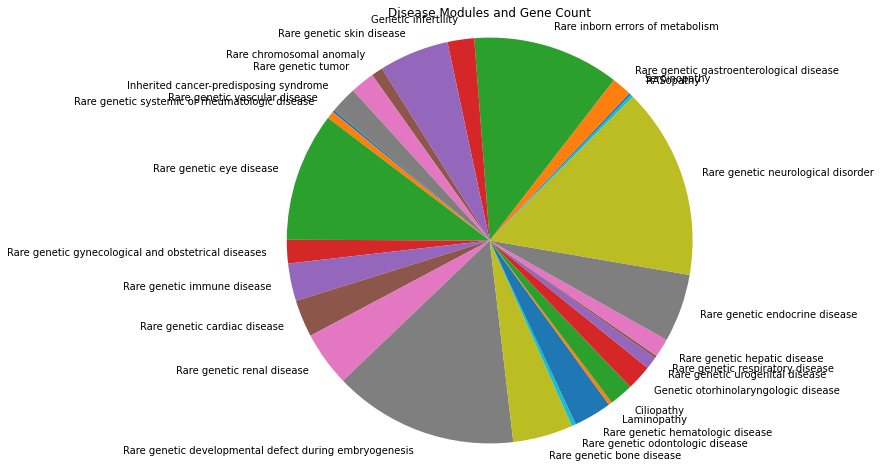

In [66]:
plt.figure(figsize=(8, 8))
plt.pie(disease_module_df['gene_count'], labels=disease_module_df['disease_module'], startangle=140)
plt.title('Disease Modules and Gene Count')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [67]:
disease_module_df.to_csv(outputs_dir / 'disease_modules_to_genes.tsv', sep='\t', index=False)

In [68]:
# Some genes are associated with more than 1 module
# table to plot the number of genes associated with 1 module, 2 modules, 3 modules, etc.

gene_module_dict = {}

for _, row in disease_module_df.iterrows():
    gene_list = row['genes'].split(';')
    for gene in gene_list:
        if gene in gene_module_dict:
            gene_module_dict[gene] += 1
        else:
            gene_module_dict[gene] = 1
            
gene_module_df = pd.DataFrame(list(gene_module_dict.items()), columns=['gene', 'module_count'])
gene_module_df

,gene,module_count
0,SLC2A10,3
1,TGFBR2,7
2,SMAD3,2
3,NKX2-5,6
4,SMAD6,2
...,...,...
1271,HABP2,1
1272,MSR1,1
1273,PMS1,2
1274,MLH3,2


In [69]:
module_count = gene_module_df.module_count.value_counts().sort_index()
module_counts_df = pd.DataFrame(module_count)
module_counts_df.to_csv(outputs_dir / 'module_counts.tsv', sep='\t', index=False)

<Axes: xlabel='module_count'>

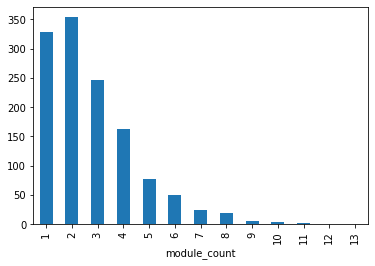

In [70]:
gene_module_df.module_count.value_counts().sort_index().plot(kind='bar')

## Inheritance patterns

In [71]:
omim_ids = set()

for omim_list in allele_collection_df['OMIM_IDs'].dropna():
    omim_ids.update(omim_list)


In [72]:
api_key = open(inputs_dir / 'OMIM_api_key.txt', 'r').read() # create the file with your own api key

In [73]:
import itertools, time, re, requests
from typing import Iterable, List, Optional, Union
from urllib3.util.retry import Retry
from requests.adapters import HTTPAdapter

# ---------- one session, automatic retries ----------
def _session(max_retries=5, backoff=0.5):
    r = Retry(total=max_retries,
              backoff_factor=backoff,
              status_forcelist=[429, 500, 502, 503, 504],
              allowed_methods=["GET"])
    s = requests.Session()
    s.mount("https://", HTTPAdapter(max_retries=r))
    s.headers["User-Agent"] = "omim-inheritance-fetch/0.1"
    return s

S = _session()

_split = re.compile(r"[;,/]")

def _inheritance(entry: dict) -> List[str]:
    pml = (entry.get("phenotypeMapList") or
           entry.get("geneMap", {}).get("phenotypeMapList"))
    raw = (
        [pm["phenotypeMap"]["phenotypeInheritance"]
         for pm in pml or []
         if pm.get("phenotypeMap", {}).get("phenotypeInheritance")]
        or [entry.get("clinicalSynopsis", {}).get("inheritance")]  # fallback
    )
    return sorted({p.strip() for x in raw for p in _split.split(x or "") if p.strip()})

def fetch_many(ids: Iterable[Union[int, str]],
               api_key: str,
               *,
               chunk=20,
               pause=0.3) -> dict[str, Optional[List[str]]]:
    out = {}
    for grp in itertools.zip_longest(*[iter(ids)]*chunk):
        batch = [str(i) for i in grp if i is not None]
        url = ("https://api.omim.org/api/entry"
               f"?mimNumber={','.join(batch)}&include=geneMap,clinicalSynopsis"
               f"&format=json&apiKey={api_key}")
        try:
            r = S.get(url, timeout=15)
            r.raise_for_status()
            for rec in r.json().get("omim", {}).get("entryList", []):
                e = rec.get("entry", {})
                out[str(e.get("mimNumber"))] = _inheritance(e) or None
        except requests.RequestException as exc:
            for bid in batch:
                out[bid] = None                # mark failed IDs
            print(f"batch {batch} failed → {exc}")
        time.sleep(pause)
    return out


In [74]:
import json
# Check if inheritance file already exists
inheritance_file_pattern = "omim_inheritance_*.json"
existing_files = list(outputs_dir.glob(inheritance_file_pattern))

if existing_files:
    print(f"Found existing inheritance file: {existing_files[0]}")
    print("Loading inheritance data from file...")
    # Load existing inheritance data from JSON
    with open(existing_files[0], 'r') as f:
        inheritance_map = json.load(f)
    print(f"Loaded {len(inheritance_map)} inheritance mappings")
else:
    print("No existing inheritance file found. Fetching from OMIM API...")
    inheritance_map = fetch_many(omim_ids, api_key)

Found existing inheritance file: ../3_outputs/omim_inheritance_20250610_144345.json
Loading inheritance data from file...
Loaded 1954 inheritance mappings


In [75]:
# to run the API call standalone

# inheritance_map = fetch_many(omim_ids, api_key)

In [76]:
import re
from typing import Dict

# pattern that removes everything starting with the first " {" (brace & space)
_CROP_BRACES = re.compile(r"\s*\{.*")
# token must contain a-z to be meaningful
_HAS_LOWER   = re.compile(r"[a-z]")

def refine_inheritance_map(
    raw: Dict[str, Optional[List[str]]]
) -> Dict[str, Optional[List[str]]]:
    """
    Strip ontology codes and keep only human-readable inheritance terms.
    """
    clean: Dict[str, Optional[List[str]]] = {}
    for omim, items in raw.items():
        if not items:
            clean[omim] = None
            continue

        terms = {
            _CROP_BRACES.sub("", s).strip()      # cut trailing codes
            for s in items if s
        }
        terms = {
            t for t in terms
            if t and _HAS_LOWER.search(t)        # keep if it has a lowercase letter
        }

        clean[omim] = sorted(terms) or None
    return clean



In [77]:
cleaned_inheritance_map = refine_inheritance_map(inheritance_map)
cleaned_inheritance_map

{'613737': ['Autosomal dominant'],
 '607625': ['Autosomal recessive'],
 '612233': ['Autosomal recessive'],
 '609192': ['Autosomal dominant'],
 '601800': ['Autosomal dominant'],
 '614432': ['Autosomal dominant'],
 '607616': ['Autosomal recessive'],
 '251880': ['Autosomal recessive'],
 '312170': ['X-linked dominant'],
 '613575': ['Autosomal recessive'],
 '169100': ['Autosomal dominant'],
 '611590': ['Autosomal recessive'],
 '114480': ['Autosomal dominant', 'Somatic mutation'],
 '613112': ['Autosomal dominant'],
 '615355': ['Autosomal dominant'],
 '602459': ['Autosomal dominant'],
 '613978': None,
 '252500': ['Autosomal recessive'],
 '255995': ['Autosomal recessive'],
 '137215': ['Autosomal dominant'],
 '263750': ['Autosomal recessive'],
 '619051': ['Autosomal recessive'],
 '605583': ['Autosomal dominant'],
 '261515': ['Autosomal recessive'],
 '604320': ['Autosomal recessive'],
 '301071': None,
 '243400': ['Autosomal recessive'],
 '604292': ['Autosomal dominant'],
 '202700': ['Autosomal d

In [78]:
from datetime import datetime
from zoneinfo import ZoneInfo          # std-lib on Python ≥ 3.9
from pathlib import Path
import json

def save_inheritance_tsv(
    inheritance_map: Dict[str, Optional[List[str]]],
    out_dir: str = "."
) -> str:
    """
    Write `inheritance_map` to a JSON named
    omim_inheritance_YYYYMMDD_HHMMSS.json in `out_dir`.

    Parameters
    ----------
    inheritance_map : dict
        {omim_id: ["Autosomal dominant", ...] or None}
    out_dir : str
        Target directory (default = current).

    Returns
    -------
    str
        Absolute path to the file that was written.
    """
    ts = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S")
    path = Path(out_dir, f"omim_inheritance_{ts}.json").resolve()

    with open(path, 'w') as json_file:
        json.dump(inheritance_map, json_file, indent=4)

    return str(path)


In [79]:
# # Run to save file if pulled and updated from OMIM API

# file_written = save_inheritance_tsv(cleaned_inheritance_map, out_dir=outputs_dir)
# print("Saved to", file_written)


In [82]:
allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af,OMIM_IDs,OMIM_API
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,NaN,NaN,NaN,chr1,G,C,1-155240033-G-C,NaN,NaN,None
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,NaN,NaN,NaN,chr1,C,T,1-155238225-C-T,NaN,NaN,None
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,NM_000157.4,2.0,1_Pathogenic,chr1,G,A,1-155237453-G-A,NaN,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Autosomal recessive, Multi..."
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,NM_000157.4,2.0,1_Pathogenic,chr1,T,C,1-155235252-T-C,NaN,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Autosomal recessive, Multi..."
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,NM_004252.5,2.0,2_Benign,chr17,C,G,17-74749174-C-G,0.026302,[612287],Autosomal dominant
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,NM_000371.4,1.0,3_Conflicting,chr18,G,A,18-31598586-G-A,0.000079,[105210],Autosomal dominant
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,NM_000304.4,1.0,3_Conflicting,chr17,A,G,17-15259120-A-G,NaN,NaN,None
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,NM_017882.3,1.0,2_Benign,chr15,G,C,15-68218645-G-C,NaN,NaN,None
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,NM_000304.4,2.0,2_Benign,chr17,G,A,17-15230997-G-A,NaN,[162500],Autosomal dominant


In [80]:
# # George's OMIM table
# omim_inheritance_df = pd.read_csv(f'/Users/user_42/Partners HealthCare Dropbox/Maxime Tixhon/edgotyping_dropbox/large_data_files/clinical_data/inheritance/omim_id_to_inheritance_best.tsv',sep='\t')
# omim_inheritance_d = dict(zip(omim_inheritance_df.omim_id.astype(str), omim_inheritance_df.inheritance_simple))
# omim_inheritance_d

In [83]:
for i, row in allele_collection_df.iterrows():
    if row.OMIM_IDs == row.OMIM_IDs:
        inheritances = set()
        g_inheritances = set()
        for omim_id in row.OMIM_IDs:
            inheritance = cleaned_inheritance_map.get(omim_id, None)
            # g_inheritance = omim_inheritance_d.get(omim_id, None)
            # if g_inheritance is not None:
                # g_inheritances.add(g_inheritance)
            if inheritance is not None:
                for inh in inheritance:
                    inheritances.add(inh)
        allele_collection_df.at[i, "OMIM_API"] = ", ".join(inheritances)
        # allele_collection_df.at[i, "OMIM_George"] = ", ".join(g_inheritances)
    else:
        allele_collection_df.at[i, "OMIM_API"] = None
        # allele_collection_df.at[i, "OMIM_George"] = None

In [84]:
na_count = 0
single_count = 0
multiple_count = 0

for i, row in allele_collection_df.iterrows():
    if row.OMIM_API == row.OMIM_API and row.OMIM_API is not None:
        if ',' in row.OMIM_API or ';' in row.OMIM_API:
            multiple_count += 1
            allele_collection_df.at[i, 'multiple_inheritance'] = True
        else:
            single_count += 1
    else:
        na_count += 1
        
print(f"NA count: {na_count}")
print(f"Single count: {single_count}")
print(f"Multiple count: {multiple_count}")
print(f'total: {na_count + single_count + multiple_count}')

NA count: 2142
Single count: 5355
Multiple count: 991
total: 8488


In [34]:
allele_collection_df[(allele_collection_df.OMIM_API == allele_collection_df.OMIM_API) & (allele_collection_df.multiple_inheritance != allele_collection_df.multiple_inheritance)].OMIM_API.value_counts()

OMIM_API
Autosomal recessive    2891
Autosomal dominant     1805
X-linked recessive      347
                        210
X-linked dominant        73
X-linked                 47
Y-linked                  6
Multifactorial            2
Digenic recessive         2
Name: count, dtype: int64

In [ ]:
from Bio.PDB.Polypeptide import three_to_one
import re

def three_to_short(hgvs: str) -> str:
    """
    Convert “Val54Leu” → “V54L”, etc.
    Raises ValueError if it can’t parse or the code isn’t recognized.
    """
    m = re.match(r'^([A-Za-z]{3})(\d+)([A-Za-z]{3})$', hgvs)
    if not m:
        raise ValueError(f"Can't parse '{hgvs}'; expected format XxxNNNYYY")
    aa_from, pos, aa_to = m.groups()
    try:
        one_from = three_to_one(aa_from.upper())
        one_to   = three_to_one(aa_to.upper())
    except KeyError:
        raise ValueError(f"Unrecognized three‐letter code in '{hgvs}'")

    return f"{one_from}{pos}{one_to}"


allele_collection_df['aa_change_1_letter'] = [three_to_short(x) for x in allele_collection_df['aa_change']]
allele_collection_df

V54L
G12D
M1T


/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(


,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,NaN,chr1,G,C,1-155240033-G-C,NaN,NaN,None,NaN,V54L
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,NaN,chr1,C,T,1-155238225-C-T,NaN,NaN,None,NaN,L224F
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,1_Pathogenic,chr1,G,A,1-155237453-G-A,NaN,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Autosomal recessive, Multi...",True,R296Q
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,1_Pathogenic,chr1,T,C,1-155235252-T-C,NaN,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Autosomal recessive, Multi...",True,L483P
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,2_Benign,chr17,C,G,17-74749174-C-G,0.026302,[612287],Autosomal dominant,NaN,L110V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,3_Conflicting,chr18,G,A,18-31598586-G-A,0.000079,[105210],Autosomal dominant,NaN,D119N
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,3_Conflicting,chr17,A,G,17-15259120-A-G,NaN,NaN,None,NaN,H51R
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,2_Benign,chr15,G,C,15-68218645-G-C,NaN,NaN,None,NaN,G30A
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,2_Benign,chr17,G,A,17-15230997-G-A,NaN,[162500],Autosomal dominant,NaN,A135T


In [86]:
allele_collection_df['gene_var'] = allele_collection_df['symbol'] + ' ' + allele_collection_df['aa_change_1_letter']
allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,chrom,ref,alt,varid,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,chr1,G,C,1-155240033-G-C,NaN,NaN,None,NaN,V54L,GBA V54L
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,chr1,C,T,1-155238225-C-T,NaN,NaN,None,NaN,L224F,GBA L224F
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,chr1,G,A,1-155237453-G-A,NaN,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Autosomal recessive, Multi...",True,R296Q,GBA R296Q
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,chr1,T,C,1-155235252-T-C,NaN,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Autosomal recessive, Multi...",True,L483P,GBA L483P
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,chr17,C,G,17-74749174-C-G,0.026302,[612287],Autosomal dominant,NaN,L110V,SLC9A3R1 L110V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,chr18,G,A,18-31598586-G-A,0.000079,[105210],Autosomal dominant,NaN,D119N,TTR D119N
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,chr17,A,G,17-15259120-A-G,NaN,NaN,None,NaN,H51R,PMP22 H51R
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,chr15,G,C,15-68218645-G-C,NaN,NaN,None,NaN,G30A,CLN6 G30A
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,chr17,G,A,17-15230997-G-A,NaN,[162500],Autosomal dominant,NaN,A135T,PMP22 A135T


In [87]:
multiple_inh = allele_collection_df[allele_collection_df.multiple_inheritance == True]

In [97]:
lacoste_df = pd.read_excel(f'{inputs_dir}/lacoste_supp.xlsx', sheet_name='Variant annotation')
lacoste_df

,Gene,Variant,Variant (alternative),Collection,Phenotype annotation,dbSNP_ID,Uniprot,Mislocalized,Mislocalization phenotype,Impact score,AlphaMissense score,AlphaMissense class,GnomAD VEP frequency,Inheritance,ClinVar class,PPI phenotype,PTM residue,PTM type,Disulfide bond,HeLa expression (TPM)
0,LDHA,LDHA K222E,NaN,hmORFeome 1.1,Lactate dehydrogenase deficiency,NaN,P00338,0.0,NaN,NaN,0.0797,benign,0.000004,autosomal recessive,No data,NaN,PTM,"ubiquitination,acetylation",NaN,476.6
1,PTEN,PTEN K6N,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,P60484,0.0,NaN,0.290927,0.9988,pathogenic,NaN,somatic,No data,NaN,PTM,"ubiquitination,acetylation",NaN,24.4
2,ASS1,ASS1 K310Q,NaN,hmORFeome 1.1,Citrullinaemia,rs121908648,P00966,0.0,NaN,0.327580,0.8178,pathogenic,0.000008,autosomal recessive,VUS,NaN,PTM,ubiquitination,NaN,29.2
3,CBLB,CBLB K837R,NaN,hmORFeome 1.1,"Diabetes, type 1",NaN,Q13191,NaN,NaN,NaN,0.0715,benign,0.000000,autosomal dominant,No data,NaN,PTM,ubiquitination,NaN,6.7
4,EPHX2,EPHX2 K55R,NaN,hmORFeome 1.1,"Increased enzyme activity, association with",rs41507953,P34913,0.0,NaN,0.104332,0.0642,benign,0.086850,autosomal dominant,No data,NaN,PTM,ubiquitination,NaN,0.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3443,XPO1,XPO1 E571K,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,rs1057520009,O14980,0.0,NaN,NaN,0.9997,pathogenic,0.000004,somatic,Pathogenic/Likely pathogenic,NaN,NaN,NaN,NaN,91.3
3444,XPO1,XPO1 R553C,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,O14980,0.0,NaN,NaN,0.9945,pathogenic,0.000000,somatic,No data,NaN,NaN,NaN,NaN,91.3
3445,YTHDC1,YTHDC1 E483Q,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,Q96MU7,0.0,NaN,0.019610,0.2190,benign,0.000000,somatic,No data,NaN,NaN,NaN,NaN,18.7
3446,ZNF454,ZNF454 H462Y,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,Q8N9F8,0.0,NaN,0.234768,0.9742,pathogenic,0.000000,somatic,No data,NaN,NaN,NaN,NaN,0.0


In [89]:
lacoste_var = lacoste_df[lacoste_df['Variant'].isin(multiple_inh.gene_var)].Variant.tolist()

In [90]:
dico = lacoste_df[lacoste_df['Variant'].isin(multiple_inh.gene_var)].set_index('Variant').to_dict()['Inheritance']
dico

{'AAAS S263P': 'autosomal recessive',
 'ATM S49C': 'autosomal recessive',
 'DNM2 S619L': 'autosomal dominant',
 'PTH S23P': 'autosomal dominant',
 'RDH12 T49M': 'autosomal recessive',
 'KCNE1 T7I': 'autosomal recessive',
 'MAT1A R264H': 'autosomal recessive',
 'TP53 R337H': 'autosomal recessive',
 'ADA K80R': 'autosomal recessive',
 'ADA P297Q': 'autosomal recessive',
 'ADA Q199P': 'autosomal recessive',
 'ADA R101Q': 'autosomal recessive',
 'AGRP A67T': 'association',
 'AIPL1 R270H': 'autosomal recessive',
 'AIPL1 R302L': 'autosomal recessive',
 'AIPL1 T114I': 'autosomal recessive',
 'ALG8 G275D': 'autosomal recessive',
 'ALG8 T47P': 'autosomal recessive',
 'AQP2 E258K': 'autosomal recessive',
 'AQP2 G64R': 'autosomal recessive',
 'AQP2 T126M': 'autosomal recessive',
 'ARL6 G169A': 'autosomal recessive',
 'ARL6 T31M': 'autosomal recessive',
 'ARL6 T31R': 'autosomal recessive',
 'ATM C107Y': 'autosomal recessive',
 'AXIN2 V539M': 'association',
 'BBS1 K53E': 'autosomal recessive',
 'BB

In [91]:
allele_collection_df[allele_collection_df.gene_var.isin(lacoste_var)]

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,chrom,ref,alt,varid,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var
25,281,MVK,60T>A,His20Gln,ENSG00000110921,12,109574882,NC_000012.12:109574882:T:A,ALE00000026,CCSBVarC000026,...,chr12,T,A,12-109574882-T-A,NaN,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,H20Q,MVK H20Q
26,281,MVK,500C>T,Pro167Leu,ENSG00000110921,12,109581523,NC_000012.12:109581523:C:T,ALE00000027,CCSBVarC000027,...,chr12,C,T,12-109581523-C-T,0.000009,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,P167L,MVK P167L
27,281,MVK,613A>G,Asn205Asp,ENSG00000110921,12,109586107,NC_000012.12:109586107:A:G,ALE00000028,CCSBVarC000028,...,chr12,A,G,12-109586107-A-G,0.000027,"[260920, 175900, 260920, 610377, 610377]","Autosomal dominant, Autosomal recessive",True,N205D,MVK N205D
50,386,STAR,505G>A,Glu169Lys,ENSG00000147465,8,38146108,NC_000008.11:38146108:C:T,ALE00000051,CCSBVarC000051,...,chr8,G,A,8-38146108-G-A,NaN,"[201710, 300707]","X-linked dominant, Autosomal recessive",True,E169K,STAR E169K
100,861,LBR,1639A>G,Asn547Asp,ENSG00000143815,1,225404452,NC_000001.11:225404452:T:C,ALE00000101,CCSBVarC000101,...,chr1,A,G,1-225404452-A-G,NaN,"[215140, 169400]","Autosomal dominant, Autosomal recessive",True,N547D,LBR N547D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2910,53089,TNFRSF13B,521T>C,Val174Ala,ENSG00000240505,17,16939770,NC_000017.11:16939770:A:G,ALE00002911,CCSBVarC002911,...,chr17,T,C,17-16939770-T-C,NaN,[240500],"Autosomal dominant, Autosomal recessive",True,V174A,TNFRSF13B V174A
6084,3084,KRAS,34G>A,Gly12Ser,ENSG00000133703,12,25245351,NC_000012.12:25245351:C:T,ALE00006088,CCSBVarC006088,...,chr12,G,A,12-25245351-G-A,NaN,"[613659, 607785, 615278]","Autosomal dominant, Somatic mutation",True,G12S,KRAS G12S
6086,3084,KRAS,35G>A,Gly12Asp,ENSG00000133703,12,25245350,NC_000012.12:25245350:C:T,ALE00006090,CCSBVarC006090,...,chr12,G,A,12-25245350-G-A,NaN,"[601626, 608354, 108010, 613659, 162900, 16320...","Autosomal dominant, Somatic mutation, Somatic ...",True,G12D,KRAS G12D
6125,4453,HRAS,35G>A,Gly12Asp,ENSG00000174775,11,534288,NC_000011.10:534288:C:T,ALE00006129,CCSBVarC006129,...,chr11,G,A,11-534288-G-A,NaN,"[218040, 236750]","Autosomal dominant, Multifactorial",True,G12D,HRAS G12D


In [92]:
allele_collection_df['inheritance_lacoste'] = allele_collection_df.gene_var.map(dico)
allele_collection_df

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,ref,alt,varid,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var,inheritance_lacoste
0,2,GBA,160G>C,Val54Leu,ENSG00000177628,1,155240033,NC_000001.11:155240033:C:G,ALE0000584,CCSBVarC000001,...,G,C,1-155240033-G-C,NaN,NaN,None,NaN,V54L,GBA V54L,NaN
1,2,GBA,670C>T,Leu224Phe,ENSG00000177628,1,155238225,NC_000001.11:155238225:G:A,ALE00000002,CCSBVarC000002,...,C,T,1-155238225-C-T,NaN,NaN,None,NaN,L224F,GBA L224F,NaN
2,2,GBA,887G>A,Arg296Gln,ENSG00000177628,1,155237453,NC_000001.11:155237453:C:T,ALE00000003,CCSBVarC000003,...,G,A,1-155237453-G-A,NaN,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Autosomal recessive, Multi...",True,R296Q,GBA R296Q,NaN
3,2,GBA,1448T>C,Leu483Pro,ENSG00000177628,1,155235252,NC_000001.11:155235252:A:G,ALE00000004,CCSBVarC000004,...,T,C,1-155235252-T-C,NaN,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Autosomal recessive, Multi...",True,L483P,GBA L483P,NaN
4,25,SLC9A3R1,328C>G,Leu110Val,ENSG00000109062,17,74749174,NC_000017.11:74749174:C:G,ALE00000005,CCSBVarC000005,...,C,G,17-74749174-C-G,0.026302,[612287],Autosomal dominant,NaN,L110V,SLC9A3R1 L110V,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,ENSG00000118271,18,31598586,NC_000018.10:31598586:G:A,ALE00008468,CCSBVarC008481,...,G,A,18-31598586-G-A,0.000079,[105210],Autosomal dominant,NaN,D119N,TTR D119N,NaN
8484,7323,PMP22,152A>G,His51Arg,ENSG00000109099,17,15259120,NC_000017.11:15259120:T:C,ALE00008469,CCSBVarC008466,...,A,G,17-15259120-A-G,NaN,NaN,None,NaN,H51R,PMP22 H51R,NaN
8485,2651,CLN6,89G>C,Gly30Ala,ENSG00000128973,15,68218645,NC_000015.10:68218645:C:G,ALE00008470,CCSBVarC008436,...,G,C,15-68218645-G-C,NaN,NaN,None,NaN,G30A,CLN6 G30A,NaN
8486,7323,PMP22,403G>A,Ala135Thr,ENSG00000109099,17,15230997,NC_000017.11:15230997:C:T,ALE00008471,CCSBVarC008467,...,G,A,17-15230997-G-A,NaN,[162500],Autosomal dominant,NaN,A135T,PMP22 A135T,NaN


In [93]:
multiple_inh_lacoste = allele_collection_df[(allele_collection_df.multiple_inheritance == True) & (allele_collection_df.inheritance_lacoste == allele_collection_df.inheritance_lacoste)]
multiple_inh_lacoste

,orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,...,ref,alt,varid,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var,inheritance_lacoste
25,281,MVK,60T>A,His20Gln,ENSG00000110921,12,109574882,NC_000012.12:109574882:T:A,ALE00000026,CCSBVarC000026,...,T,A,12-109574882-T-A,NaN,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,H20Q,MVK H20Q,autosomal recessive
26,281,MVK,500C>T,Pro167Leu,ENSG00000110921,12,109581523,NC_000012.12:109581523:C:T,ALE00000027,CCSBVarC000027,...,C,T,12-109581523-C-T,0.000009,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,P167L,MVK P167L,autosomal recessive
27,281,MVK,613A>G,Asn205Asp,ENSG00000110921,12,109586107,NC_000012.12:109586107:A:G,ALE00000028,CCSBVarC000028,...,A,G,12-109586107-A-G,0.000027,"[260920, 175900, 260920, 610377, 610377]","Autosomal dominant, Autosomal recessive",True,N205D,MVK N205D,autosomal recessive
50,386,STAR,505G>A,Glu169Lys,ENSG00000147465,8,38146108,NC_000008.11:38146108:C:T,ALE00000051,CCSBVarC000051,...,G,A,8-38146108-G-A,NaN,"[201710, 300707]","X-linked dominant, Autosomal recessive",True,E169K,STAR E169K,autosomal recessive
100,861,LBR,1639A>G,Asn547Asp,ENSG00000143815,1,225404452,NC_000001.11:225404452:T:C,ALE00000101,CCSBVarC000101,...,A,G,1-225404452-A-G,NaN,"[215140, 169400]","Autosomal dominant, Autosomal recessive",True,N547D,LBR N547D,autosomal recessive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2910,53089,TNFRSF13B,521T>C,Val174Ala,ENSG00000240505,17,16939770,NC_000017.11:16939770:A:G,ALE00002911,CCSBVarC002911,...,T,C,17-16939770-T-C,NaN,[240500],"Autosomal dominant, Autosomal recessive",True,V174A,TNFRSF13B V174A,common variant
6084,3084,KRAS,34G>A,Gly12Ser,ENSG00000133703,12,25245351,NC_000012.12:25245351:C:T,ALE00006088,CCSBVarC006088,...,G,A,12-25245351-G-A,NaN,"[613659, 607785, 615278]","Autosomal dominant, Somatic mutation",True,G12S,KRAS G12S,somatic
6086,3084,KRAS,35G>A,Gly12Asp,ENSG00000133703,12,25245350,NC_000012.12:25245350:C:T,ALE00006090,CCSBVarC006090,...,G,A,12-25245350-G-A,NaN,"[601626, 608354, 108010, 613659, 162900, 16320...","Autosomal dominant, Somatic mutation, Somatic ...",True,G12D,KRAS G12D,somatic
6125,4453,HRAS,35G>A,Gly12Asp,ENSG00000174775,11,534288,NC_000011.10:534288:C:T,ALE00006129,CCSBVarC006129,...,G,A,11-534288-G-A,NaN,"[218040, 236750]","Autosomal dominant, Multifactorial",True,G12D,HRAS G12D,somatic


In [94]:
def clean_inheritance_pattern(inheritance_string):
    """
    Intelligently clean inheritance patterns by analyzing the components.
    
    Parameters
    ----------
    inheritance_string : str or None
        Raw inheritance pattern string from OMIM API
        
    Returns
    -------
    str or None
        Cleaned inheritance pattern based on logical rules
    """
    
    
    if inheritance_string is None or inheritance_string == '':
        return None

    inheritance_string = inheritance_string.lower().strip()

    
    if not ',' in inheritance_string and not ';' in inheritance_string:
        # If no commas or semicolons, return as is
        return inheritance_string.strip()
    
    # Split on both commas and semicolons to get all components
    components = []
    for part in inheritance_string.replace(';', ',').split(','):
        part = part.strip()
        if part:
            components.append(part)
    
    # Remove duplicates while preserving order
    seen = set()
    unique_components = []
    for comp in components:
        if comp not in seen:
            seen.add(comp)
            unique_components.append(comp)
    
    # Define core inheritance patterns
    core_patterns = {
        'autosomal dominant',
        'autosomal recessive', 
        'x-linked recessive',
        'x-linked dominant',
        'x-linked',
        'y-linked',
        'multifactorial',
        'digenic recessive',
        'digenic dominant'
    }
    
    # Define modifier patterns that don't change the core inheritance
    modifiers = {
        'somatic mutation',
        'somatic mosaicism', 
        'isolated cases'
    }
    
    # Extract core patterns from components
    found_cores = []
    for comp in unique_components:
        if comp in core_patterns:
            found_cores.append(comp)
        elif any(core in comp for core in core_patterns):
            # Handle cases like "Autosomal recessive; Digenic recessive"
            for core in core_patterns:
                if core in comp:
                    found_cores.append(core)
                    break
    
    # Remove duplicates from found cores
    found_cores = list(dict.fromkeys(found_cores))
    
    # Apply cleaning logic
    if not found_cores:
        return inheritance_string  # Return original if no recognized patterns
    
    # Single pattern - return as is (ignoring modifiers)
    if len(found_cores) == 1:
        core = found_cores[0]
        # Special handling for X-linked variants
        if 'x-linked recessive' in found_cores or 'x-linked dominant' in found_cores:
            return core
        elif core == 'x-linked':
            # Check if we have both recessive and dominant
            has_recessive = any('recessive' in comp for comp in unique_components)
            has_dominant = any('dominant' in comp for comp in unique_components)
            if has_recessive and has_dominant:
                return 'x-linked'
            elif has_recessive:
                return 'x-linked recessive'
            elif has_dominant:
                return 'x-linked dominant'
            else:
                return 'x-linked'
        return core
    
    # Multiple patterns - check for conflicts
    autosomal_patterns = [p for p in found_cores if p.startswith('autosomal')]
    xlinked_patterns = [p for p in found_cores if p.startswith('x-linked')]
    other_patterns = [p for p in found_cores if not p.startswith(('autosomal', 'x-linked'))]
    
    # X-linked consolidation
    if len(xlinked_patterns) > 1:
        if 'x-linked' in xlinked_patterns:
            return 'x-linked'  # Generic X-linked when multiple X-linked types
        else:
            return 'x-linked'  # Multiple specific X-linked = generic X-linked
    
    # Autosomal conflict detection
    if 'autosomal dominant' in autosomal_patterns and 'autosomal recessive' in autosomal_patterns:
        return 'multiple'
    
    # Cross-inheritance conflicts
    if autosomal_patterns and xlinked_patterns:
        return 'multiple'
    
    # Digenic conflicts with different autosomal patterns
    digenic_patterns = [p for p in found_cores if 'digenic' in p]
    if digenic_patterns and len(autosomal_patterns) > 0:
        if len(set(autosomal_patterns)) > 1:  # Multiple different autosomal patterns
            return 'multiple'
        # Single autosomal + digenic = keep the autosomal
        return autosomal_patterns[0]
    
    # Y-linked with anything else is multiple
    if 'y-linked' in found_cores and len(found_cores) > 1:
        return 'multiple'
    
    # If we have only one type of pattern, return it
    if autosomal_patterns and not xlinked_patterns and not other_patterns:
        return autosomal_patterns[0]
    
    if xlinked_patterns and not autosomal_patterns and not other_patterns:
        return xlinked_patterns[0]
    
    
    # Default to multiple for complex cases
    return 'multiple'

# Test with some examples from your dictionary
test_cases = [
    "Autosomal dominant",
    "Autosomal recessive, Autosomal dominant", 
    "X-linked recessive, X-linked dominant",
    "Autosomal dominant; Somatic mutation",
    "Autosomal recessive; Digenic recessive",
    "X-linked recessive, Autosomal recessive, Autosomal dominant"
]

for case in test_cases:
    result = clean_inheritance_pattern(case)
    print(f"'{case}' -> '{result}'")

'Autosomal dominant' -> 'autosomal dominant'
'Autosomal recessive, Autosomal dominant' -> 'multiple'
'X-linked recessive, X-linked dominant' -> 'x-linked'
'Autosomal dominant; Somatic mutation' -> 'autosomal dominant'
'Autosomal recessive; Digenic recessive' -> 'autosomal recessive'
'X-linked recessive, Autosomal recessive, Autosomal dominant' -> 'multiple'


In [96]:
allele_collection_df['inheritance_clean'] = None

for i, row in allele_collection_df.iterrows():
    if row.inheritance_lacoste == row.inheritance_lacoste and row.inheritance_lacoste != 'association':
        allele_collection_df.at[i, 'inheritance_clean'] = row.inheritance_lacoste
    elif row.OMIM_API == row.OMIM_API:
        allele_collection_df.at[i, 'inheritance_clean'] = clean_inheritance_pattern(row.OMIM_API)
    else:
        allele_collection_df.at[i, 'inheritance_clean'] = None
        
allele_collection_df['inheritance_clean'].value_counts()

inheritance_clean
autosomal recessive    2997
autosomal dominant     1951
multiple                682
x-linked recessive      351
x-linked                 77
x-linked dominant        75
y-linked                  6
common variant            5
somatic                   4
multifactorial            3
digenic recessive         2
unclear phenotype         1
somatic mutation          1
Name: count, dtype: int64

# gencc

In [98]:
gencc_df = pd.read_csv(f'{inputs_dir}/gencc-submissions.tsv', sep='\t')
gencc_df

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_submitter_name,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,Ambry Genetics,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,Ambry Genetics,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,Ambry Genetics,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06


In [99]:
gencc_df.moi_title.unique()

array(['Autosomal dominant', 'Autosomal recessive', 'X-linked', 'Unknown',
       'Y-linked inheritance', 'Mitochondrial', 'Semidominant',
       'X-linked recessive'], dtype=object)

In [72]:
gencc_df[gencc_df['disease_original_curie'] == gencc_df['submitted_as_disease_id']]

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_submitter_name,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,Ambry Genetics,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,Ambry Genetics,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,Ambry Genetics,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06


In [100]:
gencc_df['OMIM_ID'] = gencc_df['submitted_as_disease_id'].str.split(':').str[1]
gencc_df

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date,OMIM_ID
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24,182212
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24,171300
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17,118210
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17,617532
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24,616291
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06,289
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06,289
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06,1349
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06,963


In [101]:
gencc_d = gencc_df.set_index('OMIM_ID')['moi_title'].to_dict()
gencc_d

{'182212': 'Autosomal dominant',
 '171300': 'Autosomal dominant',
 '118210': 'Autosomal dominant',
 '617532': 'Autosomal recessive',
 '616291': 'Autosomal recessive',
 '239510': 'Autosomal recessive',
 '614756': 'Autosomal dominant',
 '606324': 'Autosomal recessive',
 '617524': 'Autosomal dominant',
 '615006': 'Autosomal recessive',
 '618437': 'Autosomal recessive',
 '615528': 'Autosomal recessive',
 '0018997': 'Autosomal recessive',
 '613707': 'Autosomal dominant',
 '115150': 'Autosomal dominant',
 '613706': 'Autosomal dominant',
 '613563': 'Autosomal dominant',
 '218040': 'Autosomal dominant',
 '609942': 'Autosomal dominant',
 '615278': 'Autosomal dominant',
 '616564': 'Autosomal dominant',
 '615670': 'Autosomal dominant',
 '605275': 'Autosomal recessive',
 '615279': 'Autosomal dominant',
 '0007893': 'Autosomal dominant',
 '615280': 'Autosomal dominant',
 '618499': 'Autosomal dominant',
 '601321': 'Autosomal dominant',
 '162200': 'Autosomal dominant',
 '613224': 'Autosomal dominant',

In [102]:
allele_collection_df['gencc_inheritance'] = None

for i, row in allele_collection_df.iterrows():
    if row.OMIM_IDs == row.OMIM_IDs:
        gencc_inheritance = set()
        for omim_id in row.OMIM_IDs:
            inheritance = gencc_d.get(omim_id, None)
            if inheritance is not None:
                gencc_inheritance.add(inheritance)
        allele_collection_df.at[i, 'gencc_inheritance'] = ', '.join(gencc_inheritance) if gencc_inheritance else None
    else:
        allele_collection_df.at[i, 'gencc_inheritance'] = None
        
        
allele_collection_df['gencc_inheritance'] = allele_collection_df['gencc_inheritance'].str.lower()
allele_collection_df['gencc_inheritance'].value_counts()

gencc_inheritance
autosomal recessive                                      2983
autosomal dominant                                       1978
x-linked                                                  490
autosomal dominant, autosomal recessive                   381
unknown                                                   101
autosomal dominant, unknown                                46
unknown, autosomal recessive                               42
autosomal dominant, unknown, autosomal recessive           24
semidominant                                               15
autosomal dominant, autosomal recessive, semidominant       5
x-linked, autosomal recessive                               3
autosomal recessive, x-linked                               2
autosomal dominant, x-linked                                2
x-linked, autosomal dominant, autosomal recessive           1
autosomal dominant, autosomal recessive, x-linked           1
x-linked, semidominant                              

In [103]:
allele_collection_df['gencc_clean'] = allele_collection_df['gencc_inheritance'].apply(clean_inheritance_pattern)
allele_collection_df['gencc_clean'].value_counts()

gencc_clean
autosomal recessive    3026
autosomal dominant     2024
x-linked                490
multiple                420
unknown                 101
semidominant             15
x-linked dominant         1
Name: count, dtype: int64

In [104]:
allele_collection_df['inheritance_clean'] = allele_collection_df['inheritance_clean'].fillna(allele_collection_df['gencc_clean'])

In [105]:
allele_collection_df.inheritance_clean.value_counts()

inheritance_clean
autosomal recessive    3050
autosomal dominant     2008
multiple                683
x-linked recessive      351
x-linked                 79
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   4
multifactorial            3
digenic recessive         2
unclear phenotype         1
somatic mutation          1
Name: count, dtype: int64

# save inheritance

In [106]:
inheritance_df = allele_collection_df[['orf_id', 'symbol', 'nt_change', 'aa_change','inheritance_clean']]

In [107]:
inheritance_df.to_csv(f'{outputs_dir}/inheritance_mapping.csv', index=False)